# A02 · Parte 1 — EDA del dataset Car Evaluation  ·  *Versión resuelta para estudio*

**Autor:** Claude

**Asignatura:** TPIA — Experto Universitario

> 📘 **Cómo usar este cuaderno.** Sigue exactamente la estructura de tu entrega (secciones 1–6). Las celdas con el icono 📘 son
> **notas de estudio**: explican *qué* se hace en cada paso, *por qué* y *qué hay que mirar* en la salida. En un informe real
> esas notas no irían; irían solo las interpretaciones (bloques "**Interpretación**").

## 1. Introducción y objetivos

El dataset *Car Evaluation* (UCI, Bohanec y Rajkovič, 1988) procede de un **modelo jerárquico de decisión** que evalúa la
aceptabilidad de un coche a partir de seis atributos: precio de compra, coste de mantenimiento, número de puertas,
capacidad de pasajeros, tamaño del maletero y seguridad estimada. La variable objetivo `class` toma cuatro valores
ordenados: `unacc` (inaceptable), `acc` (aceptable), `good` (bueno) y `vgood` (muy bueno).

**Objetivos del EDA**

1. Comprender la naturaleza de las variables (tipo, dominio, orden) y el balance de la variable objetivo.
2. Verificar la calidad de los datos: nulos, duplicados e inconsistencias.
3. Describir la distribución de cada variable.
4. Cuantificar la relación de cada atributo con `class` e identificar reglas o interacciones relevantes.
5. Extraer conclusiones útiles para una posterior fase de modelado (clasificación).

> 📘 **Por qué empezar así.** El primer paso del EDA (Tema 4) es *comprender el problema*: de dónde salen los datos y qué
> se quiere predecir. Leer `car.names` es obligatorio: ahí se dice que los datos se generaron a partir de un modelo de reglas,
> lo que condiciona todo el análisis (por ejemplo, que no haya ruido ni nulos).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.precision", 3)

## 2. Carga y comprensión de los datos

Los nombres de las columnas se toman de `car.names`. La última columna es la variable objetivo (`class`).

> 📘 `car.data` **no tiene cabecera** → `header=None` + `names=` con los nombres en el orden que indica `car.names`
> (sección *Attribute Information*). La ruta es **relativa** al cuaderno, como pide el enunciado.

In [3]:
columnas = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]
df = pd.read_csv("../datos/car/car.data", header=None, names=columnas)
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [4]:
df.shape

(1728, 7)

> 📘 **Antes de convertir tipos**, miramos los valores únicos de cada columna. Así comprobamos que coinciden con los dominios
> de `car.names` (esto ya es parte de la detección de *inconsistencias*: erratas, mayúsculas, espacios…).

In [5]:
for c in df.columns:
    print(f"{c:<9} -> {sorted(df[c].unique())}")

buying    -> ['high', 'low', 'med', 'vhigh']
maint     -> ['high', 'low', 'med', 'vhigh']
doors     -> ['2', '3', '4', '5more']
persons   -> ['2', '4', 'more']
lug_boot  -> ['big', 'med', 'small']
safety    -> ['high', 'low', 'med']
class     -> ['acc', 'good', 'unacc', 'vgood']


> 📘 Todas las variables son **categóricas ordinales** (tienen un orden natural: `low < med < high < vhigh`). Si las dejamos
> como `object`, pandas las ordena alfabéticamente (`high, low, med, vhigh`) y los gráficos y tablas salen desordenados.
> Con `pd.Categorical(..., ordered=True)` fijamos el orden correcto y además ahorramos memoria.

In [6]:
orden = {
    "buying"  : ["low", "med", "high", "vhigh"],
    "maint"   : ["low", "med", "high", "vhigh"],
    "doors"   : ["2", "3", "4", "5more"],
    "persons" : ["2", "4", "more"],
    "lug_boot": ["small", "med", "big"],
    "safety"  : ["low", "med", "high"],
    "class"   : ["unacc", "acc", "good", "vgood"]
}

# Comprobación de que ningún valor queda fuera del dominio esperado (se convertiría en NaN)
for col, categorias in orden.items():
    fuera = set(df[col].unique()) - set(categorias)
    assert not fuera, f"Valores inesperados en {col}: {fuera}"
    df[col] = pd.Categorical(df[col], categories=categorias, ordered=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   buying    1728 non-null   category
 1   maint     1728 non-null   category
 2   doors     1728 non-null   category
 3   persons   1728 non-null   category
 4   lug_boot  1728 non-null   category
 5   safety    1728 non-null   category
 6   class     1728 non-null   category
dtypes: category(7)
memory usage: 13.1 KB


### 2.1 Tipos de variables, dimensiones y balance de clases

In [6]:
resumen = pd.DataFrame({
    "tipo": ["categórica ordinal"] * df.shape[1],
    "n_categorías": df.nunique(),
    "categorías": [", ".join(orden[c]) for c in df.columns],
})
resumen

,tipo,n_categorías,categorías
buying,categórica ordinal,4,"low, med, high, vhigh"
maint,categórica ordinal,4,"low, med, high, vhigh"
doors,categórica ordinal,4,"2, 3, 4, 5more"
persons,categórica ordinal,3,"2, 4, more"
lug_boot,categórica ordinal,3,"small, med, big"
safety,categórica ordinal,3,"low, med, high"
class,categórica ordinal,4,"unacc, acc, good, vgood"


> 📘 **Comprobación del diseño.** Si multiplicamos el número de categorías de los 6 atributos: 4·4·4·3·3·3 = 1728, que es
> exactamente el número de filas. Eso sugiere que el dataset contiene **todas las combinaciones posibles una sola vez**
> (diseño factorial completo). Lo verificamos:

In [7]:
n_combinaciones = np.prod([df[c].nunique() for c in columnas[:-1]])
n_unicas = df[columnas[:-1]].drop_duplicates().shape[0]
print(f"Combinaciones teóricas: {n_combinaciones} | combinaciones distintas presentes: {n_unicas} | filas: {len(df)}")

Combinaciones teóricas: 1728 | combinaciones distintas presentes: 1728 | filas: 1728


,n,%
class,,
unacc,1210,70.02
acc,384,22.22
good,69,3.99
vgood,65,3.76


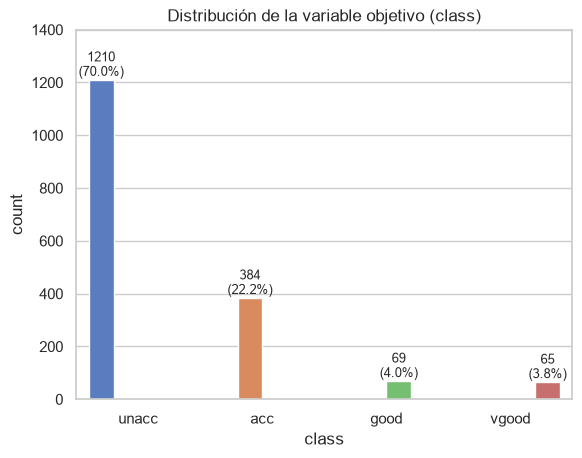

Ratio de desbalance (mayoritaria / minoritaria): 18.6 : 1


In [7]:
# Balance de la variable objetivo
balance = pd.DataFrame({
    "n": df["class"].value_counts(sort=False),
    "%": (df["class"].value_counts(normalize=True, sort=False) * 100).round(2)
})
display(balance)

ax = sns.countplot(data=df, x="class", hue="class", legend=False)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f}\n({p.get_height()/len(df):.1%})",
                (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)
ax.set_title("Distribución de la variable objetivo (class)")
ax.set_ylim(0, 1400)
plt.show()

print(f"Ratio de desbalance (mayoritaria / minoritaria): {balance['n'].max() / balance['n'].min():.1f} : 1")

**Interpretación**

- El dataset tiene **1728 observaciones y 7 variables**: 6 atributos de entrada y la variable objetivo `class`.
  Todas son **categóricas ordinales**; no hay ninguna variable numérica continua (incluso `doors` y `persons`, que parecen
  números, contienen los niveles `5more` y `more`, por lo que deben tratarse como categorías).
- Las 1728 filas corresponden exactamente a las **1728 combinaciones posibles** de los atributos: es un diseño factorial
  completo generado a partir del modelo de decisión, no una muestra de coches reales.
- La variable objetivo está **fuertemente desbalanceada**: `unacc` supone el 70,0 % de los casos, `acc` el 22,2 %, y
  `good` (4,0 %) y `vgood` (3,8 %) son minoritarias. El ratio mayoritaria/minoritaria es de ~18,6:1.
  Un clasificador trivial que predijera siempre `unacc` obtendría un 70 % de *accuracy*, por lo que esa métrica no será
  suficiente: habrá que usar *F1 macro*, matriz de confusión o *balanced accuracy*, y estratificar las particiones.

## 3. Limpieza de datos

Nulos, duplicados e inconsistencias.

> 📘 **Checklist de limpieza** que hay que hacer siempre: (1) nulos con `isna()`; (2) nulos "disfrazados" (`?`, `""`, `-1`…),
> muy típicos en UCI; (3) duplicados con `duplicated()`; (4) valores fuera de dominio (ya hecho con el `assert` de arriba);
> (5) espacios o mayúsculas raras en las cadenas.

In [9]:
print("Nulos por columna:")
print(df.isna().sum().to_string())

# Nulos "disfrazados" habituales en los ficheros de UCI
crudo = pd.read_csv("../datos/car/car.data", header=None, names=columnas, dtype=str)
marcadores = ["?", "", " ", "NA", "nan", "-"]
print("\nCeldas con marcadores de nulo:", crudo.isin(marcadores).sum().sum())

# Espacios en blanco al principio/final
print("Celdas con espacios sobrantes:", (crudo != crudo.apply(lambda s: s.str.strip())).sum().sum())

# Duplicados
print("\nFilas duplicadas completas:", df.duplicated().sum())
print("Filas con los mismos atributos y distinta clase (contradicciones):",
      df.duplicated(subset=columnas[:-1]).sum())

Nulos por columna:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0

Celdas con marcadores de nulo: 0
Celdas con espacios sobrantes: 0

Filas duplicadas completas: 0
Filas con los mismos atributos y distinta clase (contradicciones): 0


**Interpretación**

- **No hay valores nulos**, ni explícitos (`NaN`) ni codificados como `?` u otros marcadores, lo que coincide con
  `car.names` (*Missing Attribute Values: none*).
- **No hay filas duplicadas** ni tampoco **contradicciones** (mismos atributos con clase distinta): cada combinación
  aparece una sola vez, coherente con el diseño factorial completo.
- **No hay inconsistencias** de formato: todos los valores pertenecen al dominio documentado y no hay espacios sobrantes.

En consecuencia, **no es necesaria ninguna acción de limpieza**: el único preprocesado aplicado ha sido la conversión a
tipo categórico ordenado. Esto es atípico en datos reales y se explica porque el dataset es sintético (generado por reglas).

## 4. Análisis univariable

> 📘 Con variables categóricas, el análisis univariable es: **tabla de frecuencias** (absolutas y relativas) +
> **gráfico de barras**. No tienen sentido media, desviación o histograma. Para las numéricas se usarían histogramas y boxplots
> (lo verás en la Parte 2).

In [10]:
atributos = columnas[:-1]
frecuencias = pd.concat(
    {c: df[c].value_counts(sort=False).rename_axis("nivel").to_frame("n") for c in atributos}
)
frecuencias["%"] = (frecuencias["n"] / len(df) * 100).round(2)
frecuencias

n      %
         nivel            
buying   low    432  25.00
         med    432  25.00
         high   432  25.00
         vhigh  432  25.00
maint    low    432  25.00
         med    432  25.00
         high   432  25.00
         vhigh  432  25.00
doors    2      432  25.00
         3      432  25.00
         4      432  25.00
         5more  432  25.00
persons  2      576  33.33
         4      576  33.33
         more   576  33.33
lug_boot small  576  33.33
         med    576  33.33
         big    576  33.33
safety   low    576  33.33
         med    576  33.33
         high   576  33.33

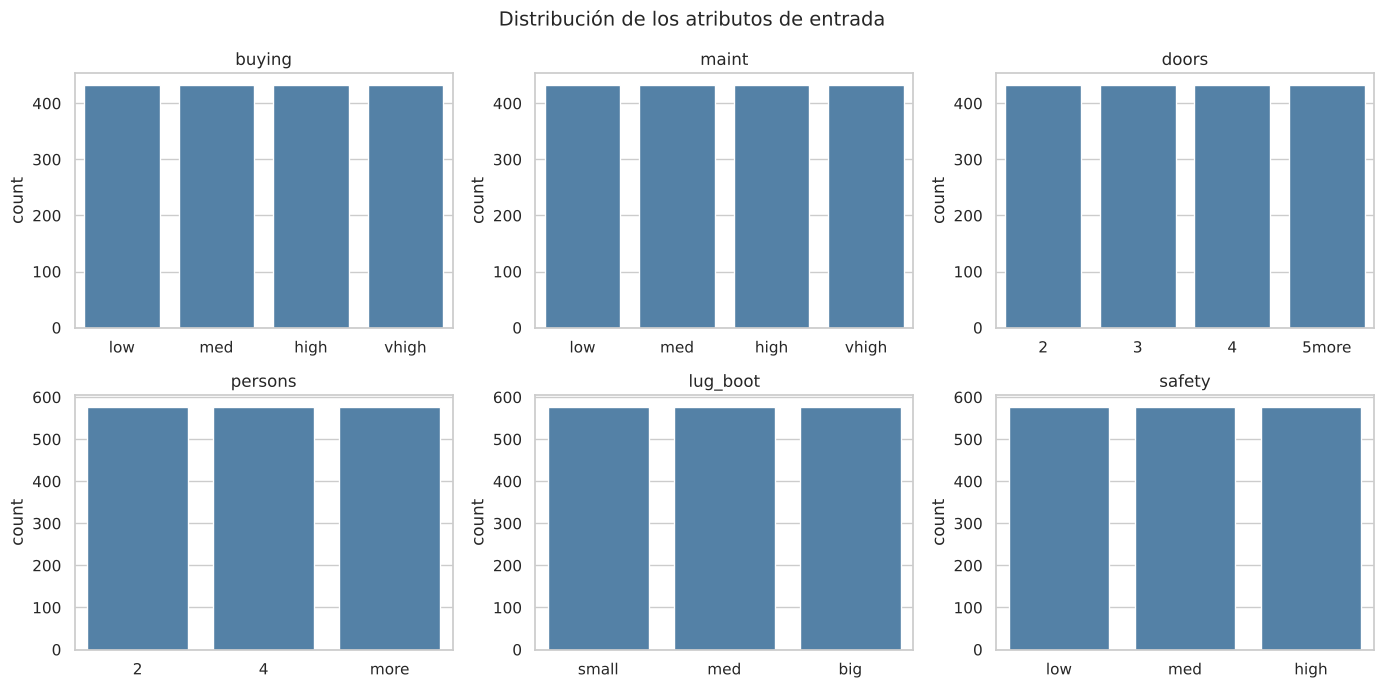

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, atributos):
    sns.countplot(data=df, x=col, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distribución de los atributos de entrada", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación**

- **Todas las variables de entrada tienen una distribución perfectamente uniforme**: cada nivel aparece 432 veces en las
  variables de 4 niveles (`buying`, `maint`, `doors`) y 576 veces en las de 3 niveles (`persons`, `lug_boot`, `safety`).
- Esto es una consecuencia directa del diseño factorial y tiene dos implicaciones: (1) los atributos **no aportan
  información por sí solos** en su distribución marginal (no hay sesgos ni categorías raras que agrupar); y (2) los
  atributos son **independientes entre sí** por construcción, de modo que **no existe multicolinealidad** (lo comprobamos en
  la sección 5).
- Toda la variabilidad interesante está, por tanto, en **cómo se relacionan los atributos con la clase**.

## 5. Análisis bivariable / multivariable

Relación de cada característica con la variable objetivo.

> 📘 **Herramientas para categórica vs. categórica:**
> - **Tabla de contingencia normalizada por filas** (`pd.crosstab(..., normalize="index")`): para cada nivel del atributo,
>   qué porcentaje cae en cada clase. Se lee *por filas*.
> - **Barras apiladas al 100 %**: la versión gráfica de lo anterior.
> - **Test χ² de independencia**: ¿la relación es estadísticamente significativa? (p < 0,05 → hay dependencia).
> - **V de Cramér**: *cuánta* asociación hay (0 = nada, 1 = total). El p-valor solo dice si existe; la V dice si es fuerte.
>   Orientativo: < 0,1 despreciable, 0,1–0,3 débil/moderada, > 0,3 fuerte.

In [12]:
def cramers_v(x, y):
    """V de Cramér a partir de la tabla de contingencia de dos variables categóricas."""
    tabla = pd.crosstab(x, y)
    chi2, p, gl, _ = chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
    return chi2, gl, p, v

asociacion = pd.DataFrame(
    [cramers_v(df[c], df["class"]) for c in atributos],
    index=atributos, columns=["chi2", "gl", "p_valor", "V_Cramer"]
).sort_values("V_Cramer", ascending=False)
asociacion["significativa (α=0,05)"] = asociacion["p_valor"] < 0.05
asociacion

,chi2,gl,p_valor,V_Cramer,"significativa (α=0,05)"
safety,479.322,6,2.389e-100,0.372,True
persons,371.337,6,4.040e-77,0.328,True
buying,189.243,9,5.928e-36,0.191,True
maint,142.941,9,2.548e-26,0.166,True
lug_boot,53.282,6,1.029e-09,0.124,True
doors,10.385,9,3.202e-01,0.045,False


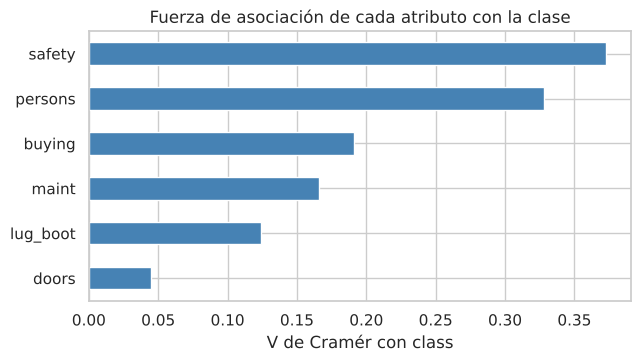

In [13]:
ax = asociacion["V_Cramer"].plot.barh(color="steelblue", figsize=(7, 3.5))
ax.invert_yaxis()
ax.set_xlabel("V de Cramér con class")
ax.set_title("Fuerza de asociación de cada atributo con la clase")
plt.show()

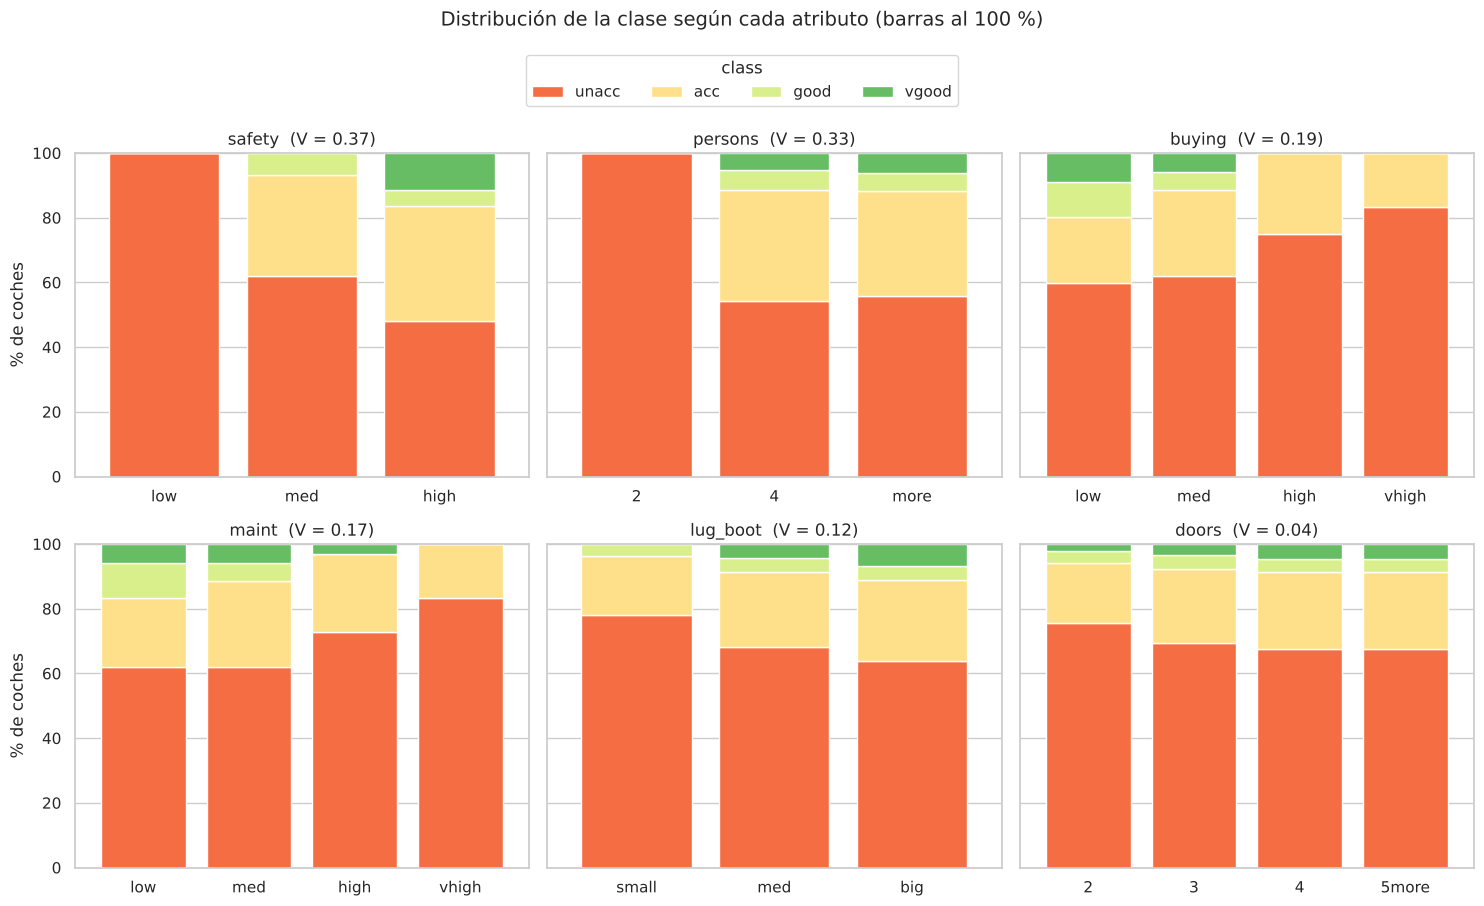

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
colores = sns.color_palette("RdYlGn", 4)
for ax, col in zip(axes.flat, asociacion.index):
    prop = pd.crosstab(df[col], df["class"], normalize="index") * 100
    prop.plot(kind="bar", stacked=True, ax=ax, color=colores, legend=False, width=0.8)
    ax.set_title(f"{col}  (V = {asociacion.loc[col, 'V_Cramer']:.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("% de coches")
    ax.tick_params(axis="x", rotation=0)
handles, labels = axes.flat[0].get_legend_handles_labels()
plt.tight_layout()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, title="class")
fig.suptitle("Distribución de la clase según cada atributo (barras al 100 %)", y=1.13, fontsize=14)
plt.show()

In [15]:
# Tablas de contingencia (% por fila) de los atributos más relevantes
for col in ["safety", "persons", "buying"]:
    print(f"\n=== {col} ===")
    display((pd.crosstab(df[col], df["class"], normalize="index") * 100).round(1))


=== safety ===


class,unacc,acc,good,vgood
safety,,,,
low,100.0,0.0,0.0,0.0
med,62.0,31.2,6.8,0.0
high,48.1,35.4,5.2,11.3



=== persons ===


class,unacc,acc,good,vgood
persons,,,,
2,100.0,0.0,0.0,0.0
4,54.2,34.4,6.2,5.2
more,55.9,32.3,5.7,6.1



=== buying ===


class,unacc,acc,good,vgood
buying,,,,
low,59.7,20.6,10.6,9.0
med,62.0,26.6,5.3,6.0
high,75.0,25.0,0.0,0.0
vhigh,83.3,16.7,0.0,0.0


**Interpretación bivariable**

- **Todos los atributos salvo `doors` están significativamente asociados con `class`** (p ≪ 0,05). `doors` tiene
  p ≈ 0,32 y V ≈ 0,05: su efecto es **despreciable**.
- Ordenados por fuerza de asociación (V de Cramér): **`safety` (0,37) > `persons` (0,33) > `buying` (0,19) > `maint` (0,17)
  > `lug_boot` (0,12) > `doors` (0,05)**.
- **`safety = low` ⇒ 100 % `unacc`** y **`persons = 2` ⇒ 100 % `unacc`**. Son **reglas deterministas**: cualquiera de estas dos
  condiciones basta para descartar el coche, independientemente del resto de atributos. Además, `vgood` solo aparece con
  `safety = high`.
- **Precio (`buying`) y mantenimiento (`maint`)** actúan de forma parecida: con valor `vhigh` el 83 % de los coches son
  `unacc` y **nunca** alcanzan `good` ni `vgood`; con `buying = high` tampoco aparecen `good` ni `vgood`. Las clases altas
  se concentran en precios y mantenimientos bajos o medios.
- **`lug_boot = small`** penaliza (78 % `unacc`) e impide alcanzar `vgood`.
- La relación es **monótona** en todos los casos: a mejor valor del atributo, mayor proporción de clases altas, lo que es
  coherente con el carácter ordinal de las variables.

### 5.1 Relaciones entre atributos e interacciones

> 📘 En el multivariable miramos dos cosas: (1) si los atributos están relacionados **entre sí** (redundancia /
> multicolinealidad) y (2) si **combinaciones** de atributos explican la clase mejor que cada uno por separado (interacciones).

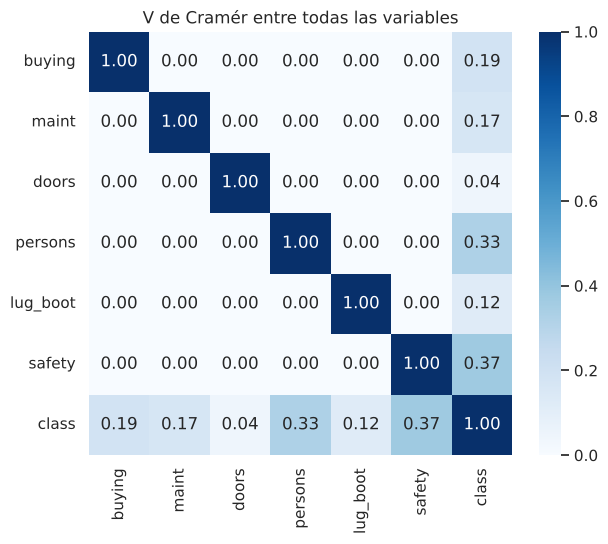

In [16]:
# Matriz de V de Cramér entre todos los pares de variables
mat = pd.DataFrame(index=columnas, columns=columnas, dtype=float)
for a in columnas:
    for b in columnas:
        mat.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])[3]

plt.figure(figsize=(7, 5.5))
sns.heatmap(mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True)
plt.title("V de Cramér entre todas las variables")
plt.show()

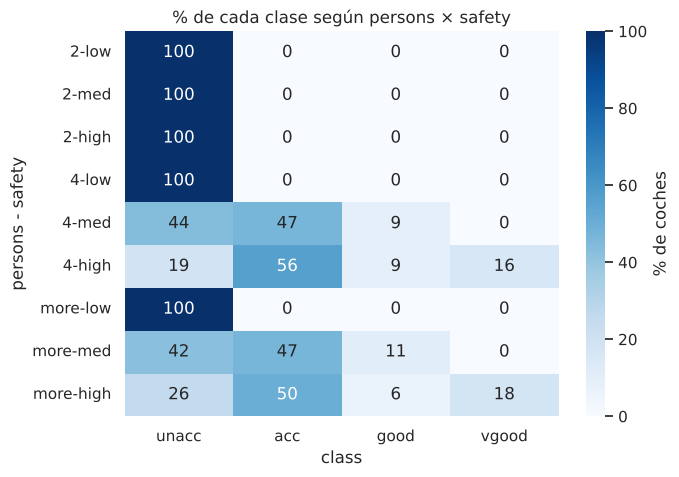

In [17]:
# Interacción de los dos atributos más relevantes
tabla_ps = pd.crosstab([df["persons"], df["safety"]], df["class"], normalize="index") * 100
plt.figure(figsize=(7, 5))
sns.heatmap(tabla_ps, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "% de coches"})
plt.title("% de cada clase según persons × safety")
plt.ylabel("persons - safety")
plt.show()

In [18]:
# ¿Cuántos 'unacc' quedan explicados por las dos reglas de descarte?
regla = (df["persons"] == "2") | (df["safety"] == "low")
print(f"Coches que cumplen persons=2 o safety=low: {regla.sum()}  -> todos unacc: {(df.loc[regla, 'class'] == 'unacc').all()}")
print(f"Porcentaje de los unacc explicados por la regla: {regla.sum() / (df['class'] == 'unacc').sum():.1%}")
print("\nClase de los coches restantes (sin descarte automático):")
print(df.loc[~regla, "class"].value_counts(sort=False).to_string())

Coches que cumplen persons=2 o safety=low: 960  -> todos unacc: True
Porcentaje de los unacc explicados por la regla: 79.3%

Clase de los coches restantes (sin descarte automático):
class
unacc    250
acc      384
good      69
vgood     65


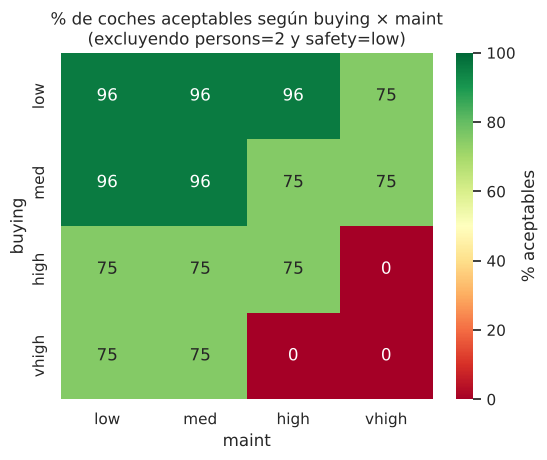

In [19]:
# Efecto combinado del coste: precio × mantenimiento sobre la proporción de coches aceptables (acc o superior)
df["aceptable"] = (df["class"] != "unacc").astype(int)
pivot = df[~regla].pivot_table(index="buying", columns="maint", values="aceptable", aggfunc="mean", observed=True) * 100
plt.figure(figsize=(6, 4.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100, cbar_kws={"label": "% aceptables"})
plt.title("% de coches aceptables según buying × maint\n(excluyendo persons=2 y safety=low)")
plt.show()
df = df.drop(columns="aceptable")

**Interpretación multivariable**

- La matriz de V de Cramér confirma que **los atributos son independientes entre sí** (V = 0 entre todos los pares): no hay
  redundancia ni multicolinealidad, y cada atributo aporta información distinta. Solo aparece asociación en la fila/columna
  de `class`.
- **Interacción `persons × safety`**: las dos reglas de descarte (`persons = 2` o `safety = low`) cubren **960 coches**, el
  **79 % de todos los `unacc`**. Entre los 768 coches restantes la distribución de clases es mucho más equilibrada
  (250 `unacc`, 384 `acc`, 69 `good`, 65 `vgood`), y es ahí donde los demás atributos marcan la diferencia.
- **Interacción `buying × maint`** (entre los coches que superan los filtros de seguridad y plazas): el coste se comporta
  de forma conjunta. Si los dos son caros (`vhigh`–`vhigh`, `vhigh`–`high` o `high`–`vhigh`) la aceptabilidad es del
  **0 %**; en las combinaciones intermedias (algún `high`, o un solo `vhigh`) se sitúa en torno al **75 %**; y con ambos en
  `low`/`med` llega al **96 %** (también `buying = low` con `maint = high`). Esto refleja la estructura jerárquica del modelo original,
  donde `buying` y `maint` se agregan en un concepto intermedio de "precio" (*PRICE*).

## 6. Conclusiones e insights

1. **Datos limpios y sintéticos.** 1728 registros sin nulos, duplicados ni inconsistencias, que cubren el producto
   cartesiano completo de los 6 atributos. No es una muestra del mundo real sino la tabla completa de un modelo de reglas;
   por eso los atributos son uniformes e independientes, y las conclusiones describen *el modelo de decisión*, no el mercado.
2. **Variable objetivo muy desbalanceada** (70 % `unacc`, ~4 % `good` y `vgood`). En el modelado habrá que estratificar
   las particiones y evaluar con métricas robustas al desbalance (F1 macro, *balanced accuracy*, matriz de confusión),
   y valorar técnicas como pesos de clase.
3. **La seguridad y la capacidad son los factores decisivos.** `safety` (V = 0,37) y `persons` (V = 0,33) son los atributos
   más asociados con la clase y actúan como **filtros eliminatorios**: `safety = low` o `persons = 2` implican siempre
   `unacc` y explican el 79 % de esa clase.
4. **El coste es el segundo bloque relevante.** `buying` y `maint` (V ≈ 0,17–0,19) tienen efecto monótono y conjunto:
   un precio o mantenimiento `vhigh` impide alcanzar `good`, y la combinación de ambos caros impide cualquier aceptación.
5. **`lug_boot` tiene efecto moderado** (un maletero pequeño impide `vgood`) y **`doors` es prácticamente irrelevante**
   (p ≈ 0,32), candidato a eliminarse en una selección de variables.
6. **Implicaciones para el modelado.** Las relaciones son monótonas y basadas en umbrales, por lo que **árboles de
   decisión** y modelos basados en reglas encajan de forma natural y serán interpretables. Para modelos que requieran
   entrada numérica conviene una **codificación ordinal** (respeta el orden) frente a *one-hot*. Dado que el dataset es
   determinista y sin ruido, es esperable obtener precisiones muy altas.

> 📘 **Plantilla mental para las conclusiones:** (1) calidad de datos, (2) objetivo y balance, (3) variables más y menos
> importantes con su métrica, (4) reglas o interacciones encontradas, (5) qué implica todo esto para el siguiente paso
> (preprocesado y modelo). Cada conclusión debe estar **respaldada por un número o gráfico** del cuaderno.